## Netflix Project - Problem Statement

### With the rapid growth of OTT and streaming platforms, users are presented with thousands of movies and TV shows, making it difficult to discover content that matches their interests. Recommendation systems play a crucial role in enhancing user experience by analyzing historical user interactions and suggesting personalized content.

### In this project, we will build a Movie Recommendation System using the Netflix Prize dataset. The objective is to analyze user ratings, movie information, and genre data to understand user preferences and generate personalized movie recommendations. The recommendation engine should be implemented using the Singular Value Decomposition (SVD) algorithm, a collaborative filtering technique that predicts user preferences based on latent factors learned from historical ratings.

  
### In addition to building the recommendation model, learners should perform Exploratory Data Analysis (EDA) to understand rating distributions, user behavior, movie popularity, and genrewise trends. The final solution should recommend movies tailored to individual users and evaluate the recommendation model using appropriate performance metrics.

### Solution Approach:

#### 1. Data Loading and Understanding
#### 2. Data Cleaning and Preprocessing
#### 3. Exploratory Data Analysis (EDA)
#### 4. Data Filtering and Preparation
#### 5. Recommendation Model Development
#### 6. Model Evaluation
#### 7. Personalized Movie Recommendations

### Data Set Links -

https://drive.google.com/file/d/1nUAwFYxnGiPhFOgP4tiXwOkaL8BgCMQG/view

https://drive.google.com/file/d/1_QXVewqmoXBF5tlr4iOPYVs_2XqrVwnF/view

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Since data is too large, we will mount the google drive directly instead of downloading and loading data in Colab

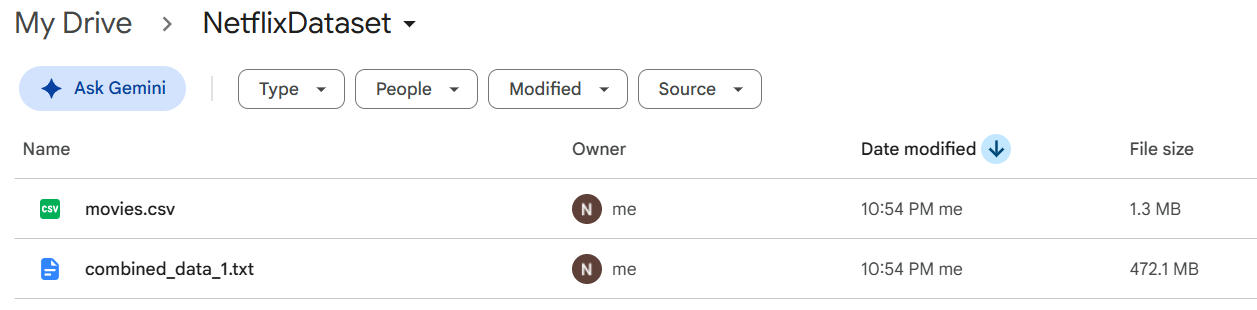

In [ ]:
from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
netflix_dataset = pd.read_csv("/content/drive/MyDrive/NetflixDataset/combined_data_1.txt", header = None, names=["Cust_Id", "Rating","Rating_Date"], usecols = [0,1,2])

# Exploratory Data Analysis (EDA)

In [ ]:
netflix_dataset.head()

,Cust_Id,Rating,Rating_Date
0,1:,NaN,NaN
1,1488844,3.0,2005-09-06
2,822109,5.0,2005-05-13
3,885013,4.0,2005-10-19
4,30878,4.0,2005-12-26


### Understanding Dataset: This dataset has movie ratings given by multiple customers on a given date.
### As observed in above result, for Movie Id 1 there are many rows. And each row is where customer (CustId) has given rating on a date to the movie. For example below.
image.png

In [ ]:
#Size of dataset - Rows and Columns
netflix_dataset.shape

(24058263, 3)

In [ ]:
#Check dataset information
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24058263 entries, 0 to 24058262
Data columns (total 3 columns):
 #   Column       Dtype  
---  ------       -----  
 0   Cust_Id      object 
 1   Rating       float64
 2   Rating_Date  object 
dtypes: float64(1), object(2)
memory usage: 550.7+ MB


In [ ]:
# CustId and RatingDate columns are of Object type, this needs to be converted to suitable datatype.

In [ ]:
# Check Null values in data set
netflix_dataset.isnull().sum()

,0
Cust_Id,0
Rating,4499
Rating_Date,4499


### We have null values only across movie ids so first we will separate them and then plan to drop the null values**

## Total number of movies

In [ ]:
# Number of movies = number of NaN values in Rating column

movie_count = netflix_dataset.isnull().sum()['Rating']
print(movie_count)

4499


### Total number of customers

In [ ]:
# Count total unique values in CustID column
total_count = netflix_dataset['Cust_Id'].nunique()
print(total_count)

475257


In [ ]:
# Count of Unique customer

customer_count = total_count - movie_count
print(customer_count)

470758


### Total number of ratings


In [ ]:
rating_count = netflix_dataset['Cust_Id'].count() - movie_count
print(rating_count)

24053764


### Extract movie id from customer id column

In [ ]:
movie_id = None
movie_id_row = []

for i in netflix_dataset['Cust_Id']:
  if ":" in i:
    movie_id = int(i.replace(":",""))

  movie_id_row.append(movie_id)

In [ ]:
movie_id_row

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


### Add MovieID column in dataset

In [ ]:
netflix_dataset['Movie_ID'] = movie_id_row

In [ ]:
netflix_dataset.head()

,Cust_Id,Rating,Rating_Date,Movie_ID
0,1:,NaN,NaN,1
1,1488844,3.0,2005-09-06,1
2,822109,5.0,2005-05-13,1
3,885013,4.0,2005-10-19,1
4,30878,4.0,2005-12-26,1


In [ ]:
# Now we can drop the rows having NaN i.e. rows with Movie ID.
netflix_dataset.dropna(inplace = True)

In [ ]:
# Recheck null values
netflix_dataset.isnull().sum()

,0
Cust_Id,0
Rating,0
Rating_Date,0
Movie_ID,0


In [ ]:
netflix_dataset.head()

,Cust_Id,Rating,Rating_Date,Movie_ID
1,1488844,3.0,2005-09-06,1
2,822109,5.0,2005-05-13,1
3,885013,4.0,2005-10-19,1
4,30878,4.0,2005-12-26,1
5,823519,3.0,2004-05-03,1


In [ ]:
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 4 columns):
 #   Column       Dtype  
---  ------       -----  
 0   Cust_Id      object 
 1   Rating       float64
 2   Rating_Date  object 
 3   Movie_ID     int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 917.6+ MB


In [ ]:
# Change datatype of Customer ID column to Int
netflix_dataset['Cust_Id'] = netflix_dataset['Cust_Id'].astype("int")

In [ ]:
# Change datatype of RatingDate column to Date
netflix_dataset['Rating_Date'] = pd.to_datetime(netflix_dataset['Rating_Date'])

In [ ]:
#Verify if changes are reflected
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 4 columns):
 #   Column       Dtype         
---  ------       -----         
 0   Cust_Id      int64         
 1   Rating       float64       
 2   Rating_Date  datetime64[ns]
 3   Movie_ID     int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 917.6 MB


In [ ]:
# Distribution of Ratings
rating_counts = netflix_dataset['Rating'].value_counts().sort_index()
print(rating_counts)

Rating
1.0    1118186
2.0    2439073
3.0    6904181
4.0    8085741
5.0    5506583
Name: count, dtype: int64


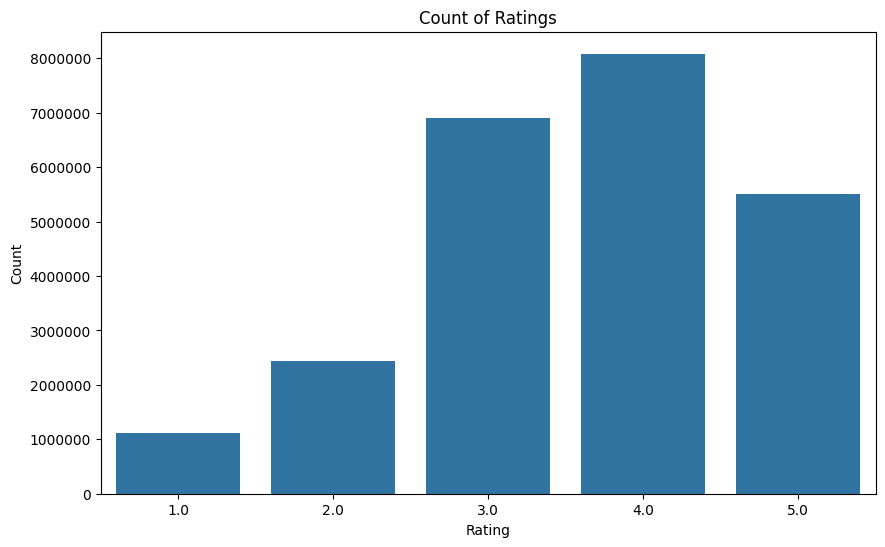

In [ ]:
# Which ratings received on which date highest number of ratings were received.
plt.figure(figsize = (10,6))
plt.ticklabel_format(style='plain', axis='y')
sns.barplot(x = rating_counts.index, y = rating_counts.values)
plt.title("Count of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

In [ ]:
# Which are the top 10 dates where highest number of ratings are received.
Highest_Rating_Dates = netflix_dataset.groupby('Rating_Date')['Rating'].count().sort_values(ascending=False).head(10)
print(Highest_Rating_Dates)

Rating_Date
2005-01-19    180428
2005-04-06     84600
2005-06-01     56269
2005-06-27     55495
2005-05-31     55175
2005-01-10     54023
2005-01-25     54020
2005-01-24     53872
2005-05-16     52929
2005-06-06     52530
Name: Rating, dtype: int64


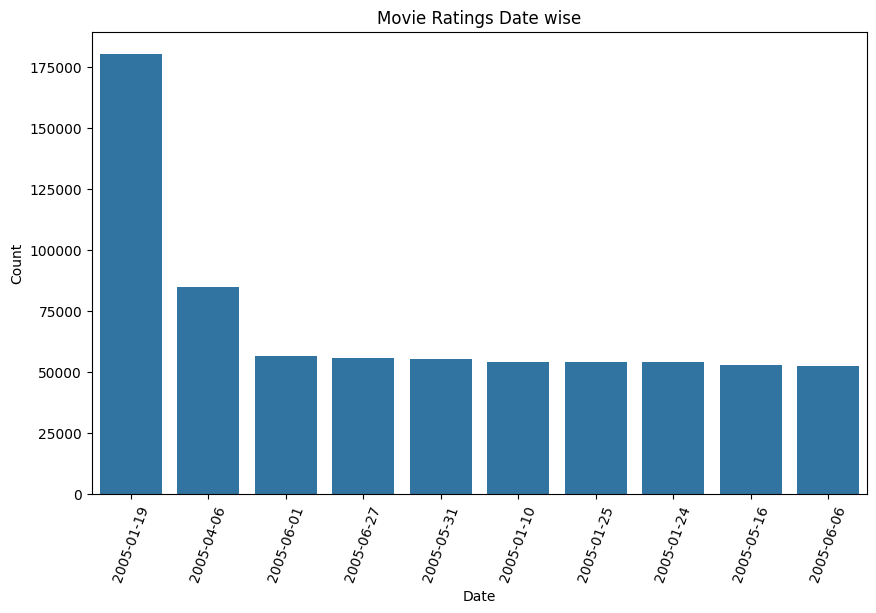

In [ ]:
plt.figure(figsize = (10,6))
sns.barplot(x = Highest_Rating_Dates.index, y = Highest_Rating_Dates.values)
plt.title("Movie Ratings Date wise")
plt.xlabel("Date")
plt.ylabel("Count")
plt.xticks(rotation = 70)
plt.show()

In [ ]:
user_ratings = netflix_dataset.groupby('Cust_Id')['Rating'].count()
user_ratings.sort_values(ascending=False).head(10)

,Rating
Cust_Id,
305344,4467
387418,4422
2439493,4195
1664010,4019
2118461,3769
1639792,2500
1314869,2467
1461435,2449
1932594,2263


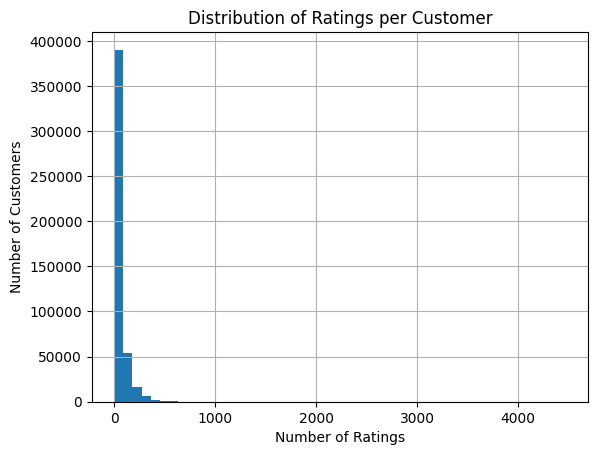

In [ ]:
user_ratings.hist(bins=50)

plt.title('Distribution of Ratings per Customer')
plt.xlabel('Number of Ratings')
plt.ylabel('Number of Customers')
plt.show()

## Create a list of movies with very few ratings

In [ ]:
summary = netflix_dataset.groupby("Movie_ID")["Rating"].agg(['count'])
summary

,count
Movie_ID,
1,547
2,145
3,2012
4,142
5,1140
...,...
4495,614
4496,9519
4497,714


In [ ]:
# now we will keep a benchmark at 20th percentile

movie_benchmark = round(np.percentile(summary['count'], 20, method = 'linear'))

In [ ]:
movie_benchmark

161

In [ ]:
drop_movie_list = summary[summary['count']<movie_benchmark].index

In [ ]:
drop_movie_list

Index([   2,    4,    7,    9,   13,   14,   20,   34,   41,   42,
       ...
       4443, 4457, 4462, 4464, 4466, 4469, 4471, 4475, 4487, 4494],
      dtype='int64', name='Movie_ID', length=899)

In [ ]:
netflix_dataset.columns

Index(['Cust_Id', 'Rating', 'Rating_Date', 'Movie_ID'], dtype='object')

In [ ]:
summary_cust = netflix_dataset.groupby("Cust_Id")["Rating"].agg(['count'])
summary_cust

,count
Cust_Id,
6,153
7,195
8,21
10,49
25,4
...,...
2649404,12
2649409,10
2649421,3


In [ ]:
cust_benchmark = round(np.percentile(summary_cust['count'], 20, method = 'linear'))

In [ ]:
cust_benchmark

7

In [ ]:
drop_cust_list = summary_cust[summary_cust['count']<cust_benchmark].index
drop_cust_list

Index([     25,     133,     149,     177,     178,     189,     215,     267,
           299,     308,
       ...
       2649024, 2649063, 2649082, 2649146, 2649240, 2649252, 2649326, 2649343,
       2649379, 2649421],
      dtype='int64', name='Cust_Id', length=93752)

In [ ]:
# Exclude the data below 20th Percentile for Movie and below Customer ID.
netflix_dataset = netflix_dataset[~netflix_dataset["Movie_ID"].isin(drop_movie_list)]
netflix_dataset = netflix_dataset[~netflix_dataset["Cust_Id"].isin(drop_cust_list)]

In [ ]:
netflix_dataset.shape

(23631748, 4)

## Importing the other dataset

In [ ]:
df_title = pd.read_csv("/content/drive/MyDrive/NetflixDataset/movies.csv", encoding = "ISO-8859-1", usecols =[0,1,2])

In [ ]:
df_title.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  27278 non-null  int64 
 1   title    27278 non-null  object
 2   genres   27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [ ]:
#Rename Movie ID column to make it same as in previous dataset
df_title.rename(columns = {'movieId': "Movie_ID"}, inplace = True)

In [ ]:
df_title.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Movie_ID  27278 non-null  int64 
 1   title     27278 non-null  object
 2   genres    27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [ ]:
df_title.head()

,Movie_ID,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


# Scikit Surprise is built specifically for recommneder tasks

In [ ]:
# pip install numpy==1.26.4

In [ ]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 19.0 MB/s  0:00:00


In [ ]:
from surprise import Reader, Dataset, SVD
from surprise.model_selection import cross_validate
from surprise.model_selection import train_test_split

In [ ]:
# Take 5% sample from the filtered dataset

sampled_data = netflix_dataset.sample(
    frac=0.05,
    random_state=42
)

print("Original records:", len(netflix_dataset))
print("Sampled records:", len(sampled_data))

Original records: 23631748
Sampled records: 1181587


In [ ]:
reader = Reader(rating_scale=(1,5))

In [ ]:
data = Dataset.load_from_df(sampled_data[['Cust_Id', 'Movie_ID','Rating']], reader)

In [ ]:
data.df.shape

(1181587, 3)

In [ ]:
# Train test split
trainset, testset = train_test_split(
    data,
    test_size=0.20,
    random_state=42
)

In [ ]:
#Model building and training
model = SVD(random_state=42)

model.fit(trainset)

In [ ]:
from surprise import accuracy

predictions = model.test(testset)

rmse = accuracy.rmse(predictions)
mae = accuracy.mae(predictions)

print("RMSE:", rmse)
print("MAE:", mae)

RMSE: 0.9982
MAE:  0.7935
RMSE: 0.9981735851716772
MAE: 0.7935328194245914


In [ ]:
cross_validate(model, data, measures = ['RMSE'], cv = 3)

{'test_rmse': array([0.99976751, 1.00105418, 1.00025954]),
 'fit_time': (15.640491962432861, 16.146878004074097, 15.9402334690094),
 'test_time': (4.935976505279541, 3.354282855987549, 4.92802095413208)}

In [ ]:
# Copy of original improved dataset
all_ratings = netflix_dataset.copy()

In [ ]:
all_ratings.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23631748 entries, 1 to 24058262
Data columns (total 4 columns):
 #   Column       Dtype         
---  ------       -----         
 0   Cust_Id      int64         
 1   Rating       float64       
 2   Rating_Date  datetime64[ns]
 3   Movie_ID     int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 901.5 MB


# Actual vs Predicted Ratings of movies by the customer

In [ ]:
user_id = 1331154

In [ ]:
# Get actual ratings given by the customer
actual_ratings = all_ratings[all_ratings['Cust_Id'] == user_id][['Movie_ID', 'Rating']].copy()

# Rename actual rating column
actual_ratings.rename(columns={'Rating': 'Actual_Rating'},inplace=True)

# Predict ratings for already-rated movies
actual_ratings['Predicted_Rating'] = actual_ratings['Movie_ID'].apply(lambda x: model.predict(user_id, int(x)).est)

# Calculate prediction error
actual_ratings['Error'] = (actual_ratings['Actual_Rating'] - actual_ratings['Predicted_Rating']).abs()

# Display comparison
actual_ratings.head(10)

,Movie_ID,Actual_Rating,Predicted_Rating,Error
697,3,4.0,3.749983,0.250017
5178,8,4.0,3.169653,0.830347
31460,18,3.0,3.693894,0.693894
92840,30,4.0,3.587404,0.412596
224761,44,3.0,3.532303,0.532303
254460,55,3.0,3.105351,0.105351
359212,108,4.0,2.944742,1.055258
415976,118,3.0,3.202706,0.202706
458308,143,5.0,4.055994,0.944006
497905,148,3.0,3.196852,0.196852


# Top 10 Recommended Movies for the customer

In [ ]:
# Get all movies already rated by this customer so we can exclude those
watched_movies = all_ratings.loc[all_ratings['Cust_Id'] == user_id,'Movie_ID'].unique()

# Create candidate movie list
user_recommendations = df_title.copy()

# Exclude movies already watched
user_recommendations = user_recommendations[~user_recommendations['Movie_ID'].isin(watched_movies)]

In [ ]:
# Exclude movies with very few ratings
user_recommendations = user_recommendations[~user_recommendations['Movie_ID'].isin(drop_movie_list)]

# Predict ratings for remaining movies
user_recommendations['Predicted_Rating'] = (user_recommendations['Movie_ID'].apply(lambda x: model.predict(user_id, int(x)).est))

# Sort by predicted rating
user_recommendations.sort_values('Predicted_Rating',ascending=False,inplace=True)

# Display Top 10 recommendations
user_recommendations.head(10)

,Movie_ID,title,genres,Predicted_Rating
3355,3444,Bloodsport (1988),Action,4.767591
1376,1409,Michael (1996),Comedy|Drama|Fantasy|Romance,4.731472
4332,4427,"Lion in Winter, The (1968)",Drama,4.670266
3336,3425,Mo' Better Blues (1990),Drama|Musical,4.638154
238,241,Fluke (1995),Children|Drama,4.633414
3367,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama,4.628119
4004,4098,"Dead, The (1987)",Drama,4.587537
1973,2057,"Incredible Journey, The (1963)",Adventure|Children,4.587467
1601,1658,"Life Less Ordinary, A (1997)",Romance|Thriller,4.583881
4144,4238,Along Came a Spider (2001),Action|Crime|Mystery|Thriller,4.562984


In [ ]:
#unmount the drive

drive.flush_and_unmount()